# 16b — CatBoost challenger

CatBoost is a gradient-boosting library that differs from LightGBM in two ways that matter here:

- **Symmetric (oblivious) trees.** Every node at the same depth uses the same split. This is a strong built-in regularizer, often useful on noisy, heavy-tailed targets like auction volume.
- **Ordered boosting.** Each row's gradient is computed from a model that hasn't seen that row, which reduces overfitting.

It usually needs less tuning than LightGBM. Its errors also tend to differ from LightGBM's, which matters if the two are later combined.

**Fair comparison with Notebook 16a.** CatBoost is trained on exactly the same rows ("large" tier: 750K tune / 150K validation / 1M refit), features (58 + 3 ratios), residual target, folds and replacement gate as `lgbm_61_ratios_large` and `lgbm_61_ratios_large_tuned`. Run Notebook 16a first; this notebook reads its predictions for the head-to-head comparison.

Hyperparameters searched on the validation year (prespecified): depth 6 or 8, combined with L2 leaf penalty 3 or 10. Learning rate 0.08, up to 3,000 trees, early stopping after 100 rounds without improvement.

In [1]:
import json
import warnings

import catboost
from catboost import CatBoostRegressor
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

import challenger_utils as cu

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")

OUT = cu.output_dir("16b_catboost_challenger")
LGBM_OUT = cu.output_dir("16a_lightgbm_improvements")
print(f"Outputs: {OUT}")
print(f"CatBoost {catboost.__version__}; smoke mode: {cu.SMOKE}")

Outputs: /Users/alisapriyadarsini/Downloads/capstone/blackrock_workspace/outputs/eda/16b_catboost_challenger
CatBoost 1.2.10; smoke mode: False


## Candidate definition

In [2]:
THREADS = 6
GRID = [
    {"depth": 6, "l2_leaf_reg": 3.0},
    {"depth": 6, "l2_leaf_reg": 10.0},
    {"depth": 8, "l2_leaf_reg": 3.0},
    {"depth": 8, "l2_leaf_reg": 10.0},
]
COMMON = {"loss_function": "RMSE", "learning_rate": 0.08, "border_count": 128,
          "thread_count": THREADS, "verbose": 0, "allow_writing_files": False}


def cat_fit(x, y, x_val, y_val, config, seed):
    model = CatBoostRegressor(iterations=3000, od_type="Iter", od_wait=100, random_seed=seed, **COMMON, **config)
    model.fit(x, y, eval_set=(x_val, y_val), use_best_model=True)
    return model, int(model.get_best_iteration()) + 1


def cat_refit(x, y, config, iterations, seed):
    model = CatBoostRegressor(iterations=iterations, random_seed=seed, **COMMON, **config)
    return model.fit(x, y)


def cat_importance(model):
    return model.get_feature_importance()


CANDIDATES = [{
    "name": "catboost_61_ratios_large", "family": "CatBoost", "tier": "large",
    "features": cu.RATIO_SET, "configs": GRID[:1] if cu.SMOKE else GRID,
    "fit": cat_fit, "refit": cat_refit, "importance": cat_importance,
}]
NAME = CANDIDATES[0]["name"]

## Rolling out-of-time run

About 1–2 hours on an 8 GB M2.

In [3]:
metrics, validation, importance = cu.run_experiment(CANDIDATES, OUT, tag="catboost")
display(metrics.pivot_table(index="candidate", columns="test_year", values="rmse_log"))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[    23s] 2022 tier=large rows={'tune': 750000, 'validation': 150000, 'refit': 1000000}


[   172s]   catboost_61_ratios_large: best config 3 (612 iters, val rmse 0.5697)


[   212s] wrote 328,634 predictions for 2022


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

... (11 outputs left out)

[   654s] 2025 tier=large rows={'tune': 750000, 'validation': 150000, 'refit': 1000000}


[   747s]   catboost_61_ratios_large: best config 3 (401 iters, val rmse 0.4279)


[   776s] wrote 307,853 predictions for 2025


test_year,2022,2023,2024,2025
candidate,,,,
catboost_61_ratios_large,0.5041,0.4563,0.4306,0.4229
rolling5_residual_auction_calendar_liquidity,0.5338,0.4838,0.4460,0.4467


## Head-to-head with Notebook 16a

CatBoost predictions are joined to Notebook 16a predictions on (date, permno). The test rows are identical: every eligible stock-day in each test year.

In [4]:
LGBM_COLUMNS = ["lgbm_58_control", "lgbm_61_ratios_large", "lgbm_61_ratios_large_tuned"]
lgbm_metrics = pd.read_csv(LGBM_OUT / "candidate_metrics.csv")
combined_dir = OUT / "combined"
combined_dir.mkdir(exist_ok=True)
for year in cu.TEST_YEARS:
    cu.con.execute(f"""
        COPY (
            SELECT c.*, {", ".join(f'l."{col}"' for col in LGBM_COLUMNS)}
            FROM read_parquet('{OUT}/predictions/catboost_predictions_{year}.parquet') c
            JOIN read_parquet('{LGBM_OUT}/predictions/lgbm_improvements_predictions_{year}.parquet') l
            USING (date, permno)
        ) TO '{combined_dir}/combined_{year}.parquet' (FORMAT PARQUET)
    """)
    joined = cu.sql(f"SELECT count(*) n FROM '{combined_dir}/combined_{year}.parquet'").n[0]
    expected = cu.sql(f"SELECT count(*) n FROM '{OUT}/predictions/catboost_predictions_{year}.parquet'").n[0]
    assert joined == expected, f"{year}: only {joined} of {expected} rows matched Notebook 16a"

all_metrics = pd.concat([metrics, lgbm_metrics[lgbm_metrics.candidate.isin(LGBM_COLUMNS)]], ignore_index=True)
GLOB = str(combined_dir / "combined_*.parquet")

tables = []
for reference in [cu.CHAMPION, "lgbm_58_control", "lgbm_61_ratios_large", "lgbm_61_ratios_large_tuned"]:
    others = [NAME] if reference != cu.CHAMPION else [NAME] + LGBM_COLUMNS
    table, _ = cu.decision_table(all_metrics, GLOB, reference, others)
    tables.append(table)
selection = pd.concat(tables, ignore_index=True)
selection.to_csv(OUT / "candidate_selection.csv", index=False)
for table in tables:
    print(f"Against {table.reference.iloc[0]}")
    display(table)

Against rolling5_residual_auction_calendar_liquidity


,candidate,reference,development_rmse_log,confirmation_rmse_log,development_wape,rmse_change_vs_reference,worst_year_change,confirmation_change,log_mae_diff,log_mae_ci_97_5,practical_improvement,stable_each_year,paired_significant,passes_gate
0,catboost_61_ratios_large,rolling5_residual_auction_calendar_liquidity,0.4637,0.4229,0.3511,-0.0242,-0.0154,-0.0237,-0.0111,-0.0068,True,True,True,True
1,lgbm_58_control,rolling5_residual_auction_calendar_liquidity,0.4725,0.4350,0.3554,-0.0153,-0.0064,-0.0117,-0.0062,-0.0021,True,True,True,True
2,lgbm_61_ratios_large,rolling5_residual_auction_calendar_liquidity,0.4654,0.4236,0.3507,-0.0225,-0.0117,-0.0230,-0.0099,-0.0055,True,True,True,True
3,lgbm_61_ratios_large_tuned,rolling5_residual_auction_calendar_liquidity,0.4636,0.4242,0.3488,-0.0243,-0.0125,-0.0225,-0.0119,-0.0075,True,True,True,True
4,rolling5_residual_auction_calendar_liquidity,rolling5_residual_auction_calendar_liquidity,0.4879,0.4467,0.3674,0.0000,0.0000,0.0000,NaN,NaN,None,None,None,None


Against lgbm_58_control


,candidate,reference,development_rmse_log,confirmation_rmse_log,development_wape,rmse_change_vs_reference,worst_year_change,confirmation_change,log_mae_diff,log_mae_ci_97_5,practical_improvement,stable_each_year,paired_significant,passes_gate
0,catboost_61_ratios_large,lgbm_58_control,0.4637,0.4229,0.3511,-0.0089,-0.0050,-0.0121,-0.0049,-0.0031,True,True,True,True
1,lgbm_58_control,lgbm_58_control,0.4725,0.4350,0.3554,0.0000,0.0000,0.0000,NaN,NaN,None,None,None,None


Against lgbm_61_ratios_large


,candidate,reference,development_rmse_log,confirmation_rmse_log,development_wape,rmse_change_vs_reference,worst_year_change,confirmation_change,log_mae_diff,log_mae_ci_97_5,practical_improvement,stable_each_year,paired_significant,passes_gate
0,catboost_61_ratios_large,lgbm_61_ratios_large,0.4637,0.4229,0.3511,-0.0017,0.0004,-0.0007,-0.0012,0.0000,False,True,False,False
1,lgbm_61_ratios_large,lgbm_61_ratios_large,0.4654,0.4236,0.3507,0.0000,0.0000,0.0000,NaN,NaN,None,None,None,None


Against lgbm_61_ratios_large_tuned


,candidate,reference,development_rmse_log,confirmation_rmse_log,development_wape,rmse_change_vs_reference,worst_year_change,confirmation_change,log_mae_diff,log_mae_ci_97_5,practical_improvement,stable_each_year,paired_significant,passes_gate
0,catboost_61_ratios_large,lgbm_61_ratios_large_tuned,0.4637,0.4229,0.3511,0.0001,0.0016,-0.0012,0.0008,0.0020,False,True,False,False
1,lgbm_61_ratios_large_tuned,lgbm_61_ratios_large_tuned,0.4636,0.4242,0.3488,0.0000,0.0000,0.0000,NaN,NaN,None,None,None,None


## Selected hyperparameters, segments and feature importance

,test_year,config_id,config,best_iteration,validation_rmse_log
3,2022,3,"{""depth"": 8, ""l2_leaf_reg"": 10.0}",612,0.5697
7,2023,3,"{""depth"": 8, ""l2_leaf_reg"": 10.0}",475,0.5071
10,2024,2,"{""depth"": 8, ""l2_leaf_reg"": 3.0}",881,0.4562
15,2025,3,"{""depth"": 8, ""l2_leaf_reg"": 10.0}",401,0.4279


candidate                     catboost_61_ratios_large  frozen_prediction  \
dimension   segment                                                         
actual_tail lower_99pct                         0.4540             0.4741   
            top_1pct                            1.1110             1.3191   
event       month_end                           0.6463             0.6866   
            monthly_expiry                      0.5433             0.5441   
            quarterly_expiry                    0.7537             0.8077   
            regular                             0.4435             0.4672   
size        large                               0.3929             0.4103   
            mid                                 0.4271             0.4479   
            small                               0.5715             0.6058   

candidate                     lgbm_61_ratios_large_tuned  
dimension   segment                                       
actual_tail lower_99pct                           0.4538  
            top_1pct                              1.1094  
event       month_end                             0.6479  
            monthly_expiry                        0.5402  
            quarterly_expiry                      0.7591  
            regular                               0.4431  
size        large                                 0.3926  
            mid                                   0.4268  
            small                                 0.5713

,test_year,catboost_vs_lgbm,catboost_vs_ridge
0,2022,0.9861,0.9251
1,2023,0.9852,0.9360
2,2024,0.9836,0.9325
3,2025,0.9841,0.9476


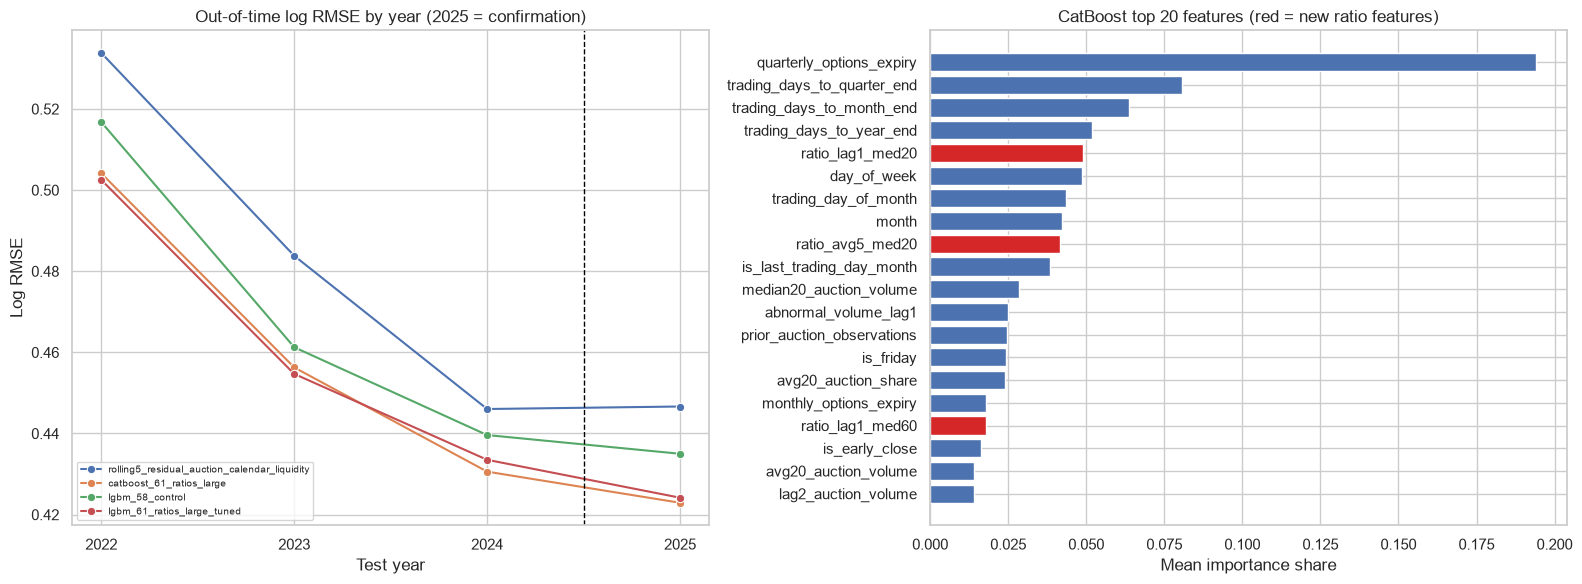

In [5]:
chosen = validation.loc[validation.groupby("test_year").validation_rmse_log.idxmin()]
display(chosen[["test_year", "config_id", "config", "best_iteration", "validation_rmse_log"]])

display(cu.segment_table(GLOB, ["frozen_prediction", "lgbm_61_ratios_large_tuned", NAME]).round(4))

# How different are CatBoost and LightGBM errors? Lower correlation = more to gain from combining them.
error_corr = cu.sql(f"""
    SELECT year(date) AS test_year,
           corr(ln(1 + {NAME}) - log1p_auction_volume, ln(1 + lgbm_61_ratios_large_tuned) - log1p_auction_volume) AS catboost_vs_lgbm,
           corr(ln(1 + {NAME}) - log1p_auction_volume, ln(1 + frozen_prediction) - log1p_auction_volume) AS catboost_vs_ridge
    FROM read_parquet('{GLOB}') GROUP BY 1 ORDER BY 1
""")
display(error_corr)

top = importance.groupby("source_feature").gain_share.mean().sort_values(ascending=False).head(20)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot = all_metrics[all_metrics.candidate.isin([cu.CHAMPION, NAME, "lgbm_58_control", "lgbm_61_ratios_large_tuned"])]
sns.lineplot(data=plot, x="test_year", y="rmse_log", hue="candidate", marker="o", ax=axes[0])
axes[0].axvline(2024.5, color="black", ls="--", lw=1)
axes[0].set_xticks(cu.TEST_YEARS)  # whole years only; otherwise matplotlib picks 0.5 steps
axes[0].set(title="Out-of-time log RMSE by year (2025 = confirmation)", xlabel="Test year", ylabel="Log RMSE")
axes[0].legend(fontsize=7)
colors = ["#d62728" if f in cu.RATIO_FEATURES else "#4c72b0" for f in top.index]
axes[1].barh(top.index[::-1], top.values[::-1], color=colors[::-1])
axes[1].set(title="CatBoost top 20 features (red = new ratio features)", xlabel="Mean importance share")
plt.tight_layout()
plt.savefig(OUT / "catboost_challenger.png", bbox_inches="tight")
plt.show()

## Conclusion

In [6]:
ridge_table = tables[0].set_index("candidate")
summary = {
    "catboost_development_rmse_log": float(ridge_table.loc[NAME, "development_rmse_log"]),
    "catboost_confirmation_rmse_log": float(ridge_table.loc[NAME, "confirmation_rmse_log"]),
    "change_vs_frozen_ridge": float(ridge_table.loc[NAME, "rmse_change_vs_reference"]),
    "passes_gate_vs": [t.reference.iloc[0] for t in tables if bool(t.set_index("candidate").loc[NAME, "passes_gate"])],
    "best_development_model_overall": ridge_table.drop(index=cu.CHAMPION).development_rmse_log.idxmin(),
    "smoke_mode": cu.SMOKE,
}
with open(OUT / "recommendation.json", "w") as handle:
    json.dump(summary, handle, indent=2)
display(summary)

{'catboost_development_rmse_log': 0.4636661821415258,
 'catboost_confirmation_rmse_log': 0.422921262306753,
 'change_vs_frozen_ridge': -0.0242141989247448,
 'passes_gate_vs': ['rolling5_residual_auction_calendar_liquidity',
  'lgbm_58_control'],
 'best_development_model_overall': 'lgbm_61_ratios_large_tuned',
 'smoke_mode': False}